# Phân tích và dự đoán bệnh tái nhập viện với bệnh tiểu đường


## 1. Cài đặt và kiểm tra dữ liệu

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", palette="deep")
sns.set_context(
    "notebook",
    font_scale=1.3,
    rc={
        "axes.titlesize": 20,
        "axes.labelsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 12,
        "figure.titlesize": 19,
    },
)

DATA_PATH = Path("src/data/diabetic_data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../src/data/diabetic_data.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Không tìm thấy src/data/diabetic_data.csv tại thư mục hiện tại.")

raw_data = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Kích thước dữ liệu: {raw_data.shape[0]:,} dòng x {raw_data.shape[1]} cột")
display(raw_data.head())
print("\nKiểu dữ liệu:")
display(raw_data.dtypes.rename("dtype").to_frame())

Kích thước dữ liệu: 101,766 dòng x 50 cột


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Kiểu dữ liệu:


,dtype
encounter_id,int64
patient_nbr,int64
race,object
gender,object
age,object
weight,object
admission_type_id,int64
discharge_disposition_id,int64
admission_source_id,int64
time_in_hospital,int64


## 2. Phân bổ thuộc tính

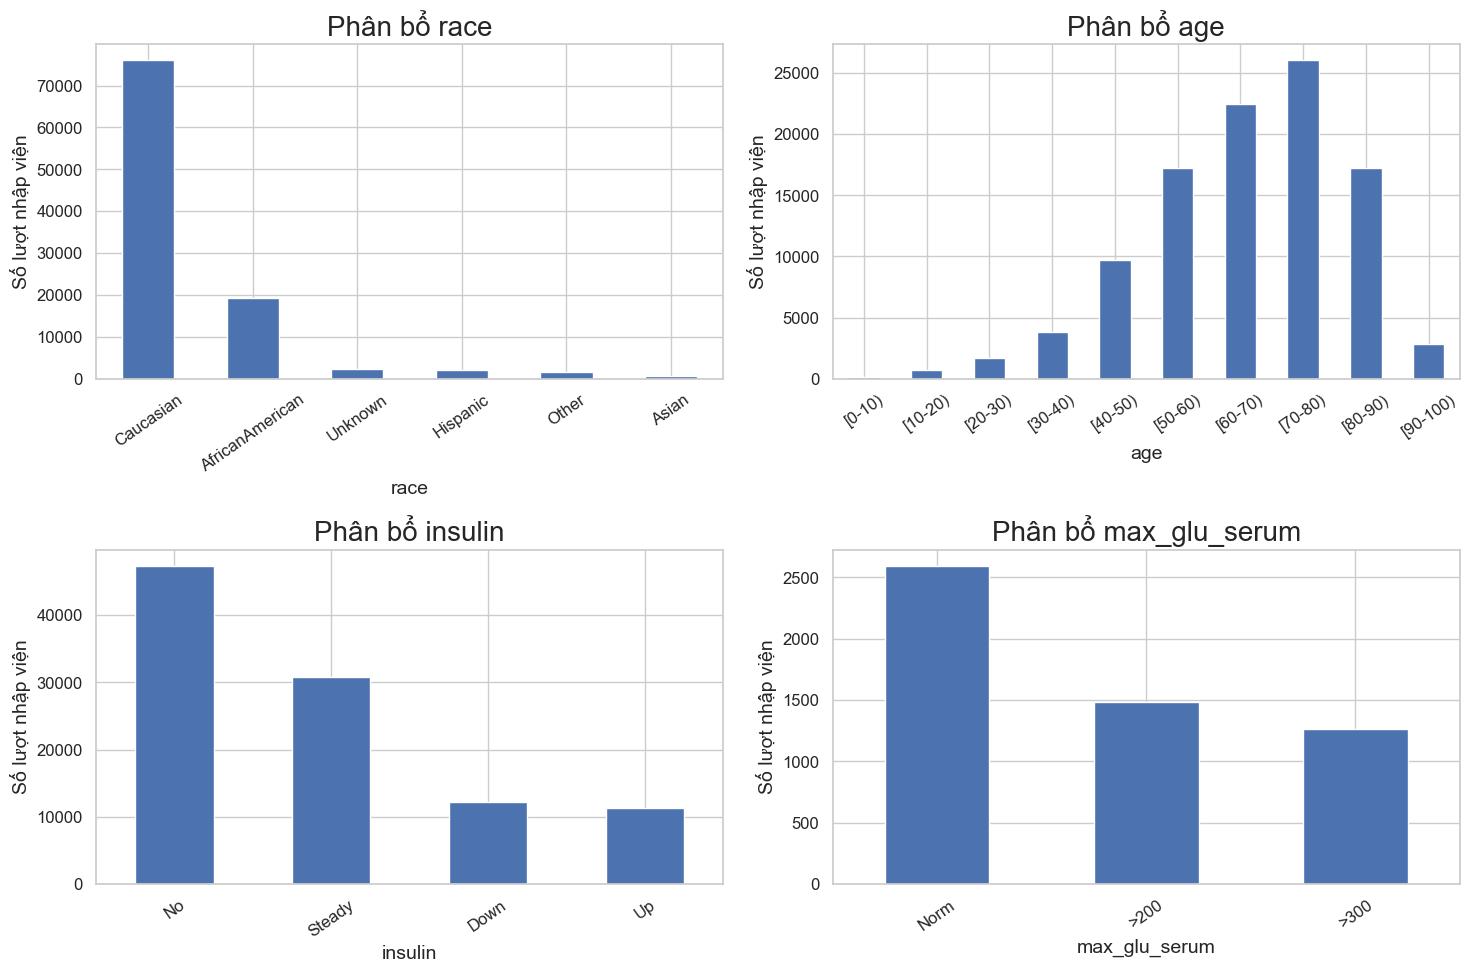

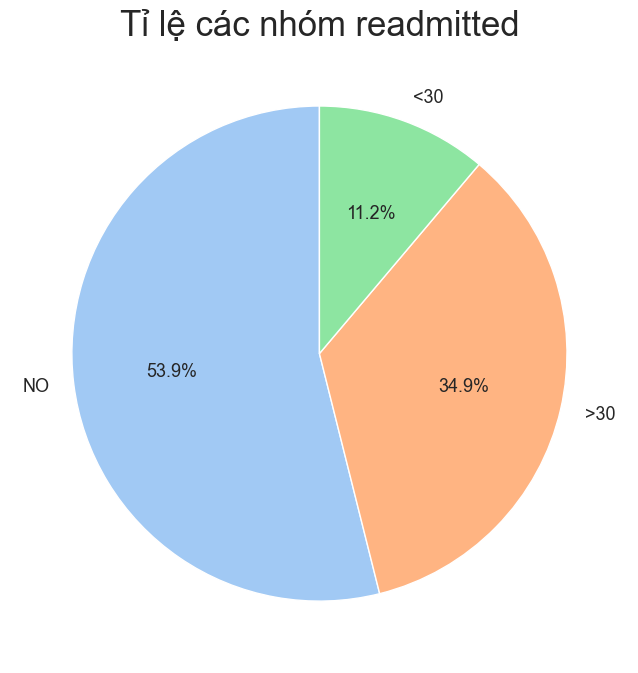

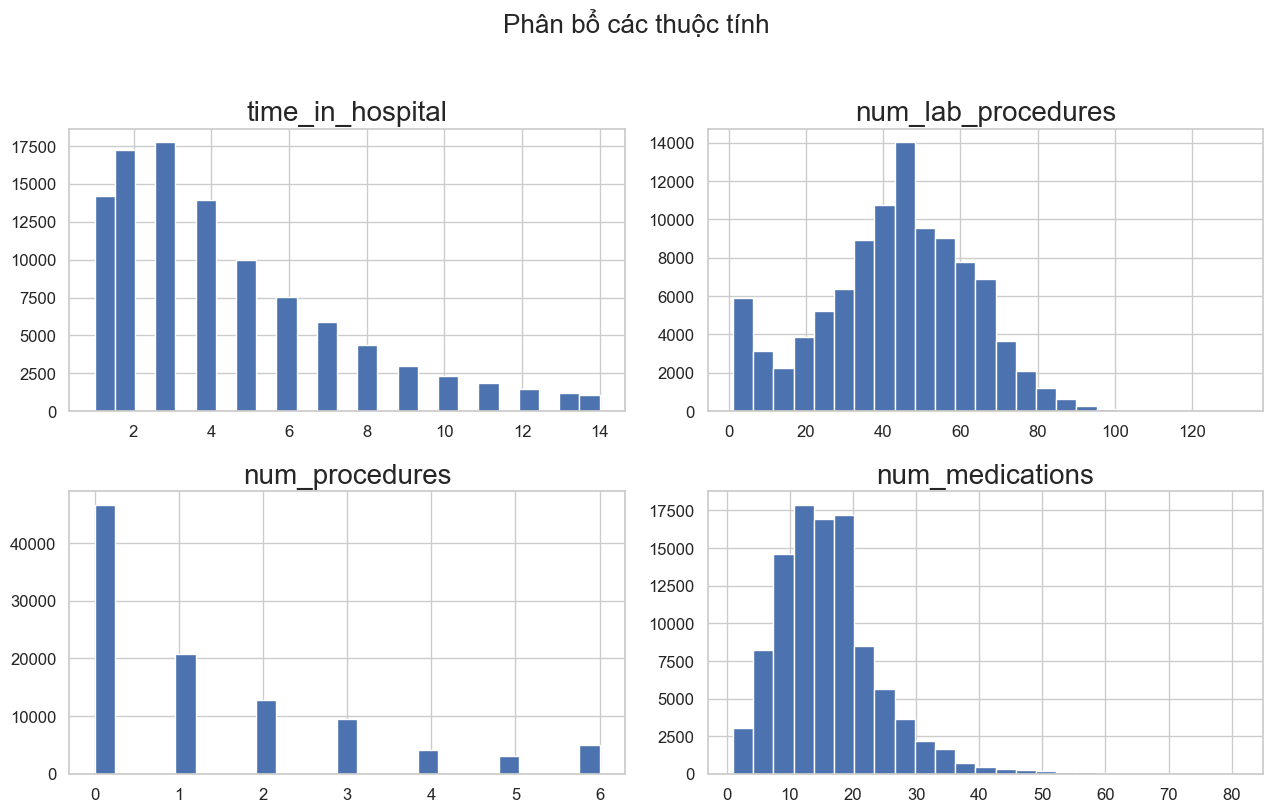

In [2]:
distribution_columns = ["race", "age", "insulin", "max_glu_serum"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for column, ax in zip(distribution_columns, axes.flat):
    values = raw_data[column].replace("?", "Unknown")
    counts = values.value_counts()
    if column == "age":
        counts = counts.reindex(values.drop_duplicates().tolist(), fill_value=0)
    else:
        counts = counts.head(12)
    counts.plot(kind="bar", ax=ax, color=sns.color_palette("deep")[0])
    ax.set_title(f"Phân bổ {column}")
    ax.set_xlabel(column, fontsize=14)
    ax.set_ylabel("Số lượt nhập viện")
    ax.tick_params(axis="x", rotation=35, labelsize=12)
    ax.tick_params(axis="y", labelsize=12)
fig.tight_layout()
plt.show()

readmission_counts = raw_data["readmitted"].value_counts()
fig, ax = plt.subplots(figsize=(7, 7))
readmission_counts.plot(
    kind="pie", autopct="%1.1f%%", startangle=90, ax=ax,
    colors=sns.color_palette("pastel", len(readmission_counts)),
    textprops={"fontsize": 13},
)
ax.set_title("Tỉ lệ các nhóm readmitted", fontsize=25,)
ax.set_ylabel("", fontsize=20)
plt.tight_layout()
plt.show()

numeric_distribution_columns = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications"
]
raw_data[numeric_distribution_columns].hist(bins=25, figsize=(13, 8), layout=(2, 2))
plt.suptitle("Phân bổ các thuộc tính", y=1.02)
plt.tight_layout()
plt.show()

## 3. Ma trận tương quan

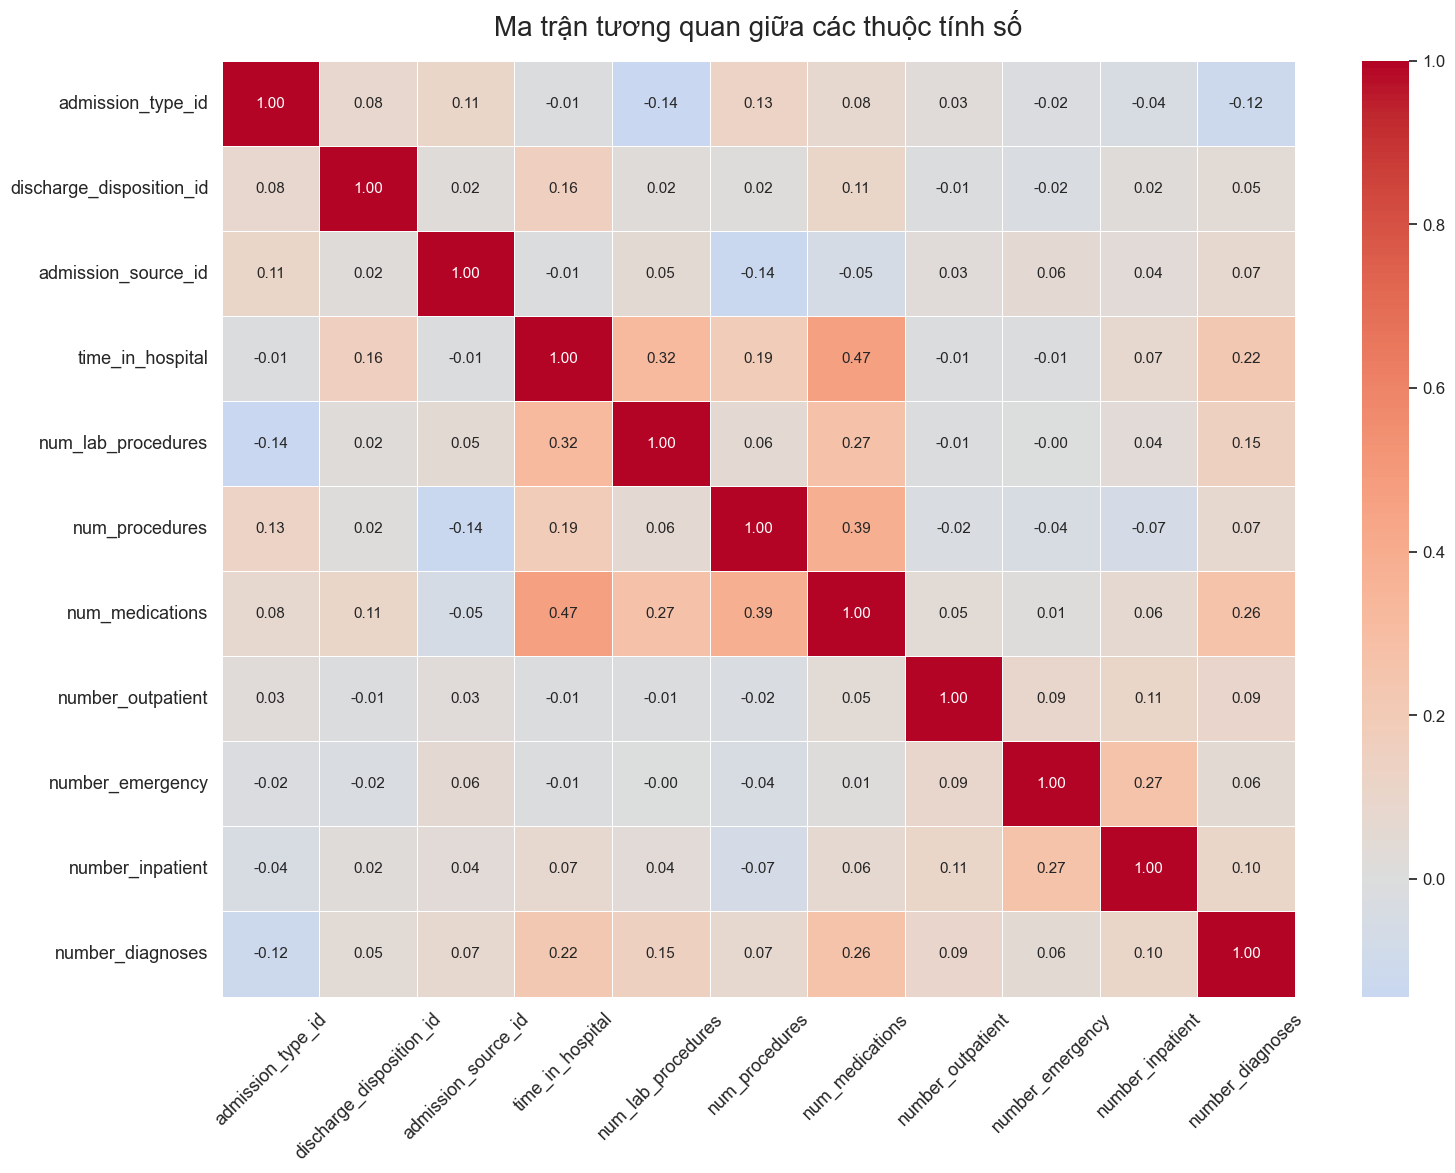

In [3]:
numeric_data = raw_data.select_dtypes(include="number").drop(
    columns=["encounter_id", "patient_nbr"], errors="ignore"
)
correlation = numeric_data.corr()
fig, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 11},
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Ma tr\u1eadn t\u01b0\u01a1ng quan gi\u1eefa c\u00e1c thu\u1ed9c t\u00ednh s\u1ed1", fontsize=20, pad=18)
ax.tick_params(axis="x", labelsize=13, rotation=45)
ax.tick_params(axis="y", labelsize=13, rotation=0)
plt.tight_layout()
plt.show()


diag_1, diag_2, diag_3 lần lượt lưu mã chẩn đoán chính, chẩn đoán thứ hai và chẩn đoán thứ ba.

Các giá trị quan sát được là mã ICD-9-CM ở dạng chuỗi. Trong đó, nhóm mã V (ví dụ: V57, liên quan đến chăm sóc và phục hồi chức năng) và nhóm mã E cũng là những mã chẩn đoán hợp lệ.

Vì mã chẩn đoán là thuộc tính phân loại (categorical), không phải đại lượng đo lường, nên việc thay thế các giá trị thiếu bằng giá trị trung bình là không phù hợp và không có ý nghĩa thống kê.

Do đó, các mã chẩn đoán hợp lệ được giữ nguyên và mã hóa bằng phương pháp One-Hot Encoding. Những giá trị ? được xem là dữ liệu khuyết (missing values) và được xử lý tương ứng.

## 4. Tiền xử lý dữ liệu và chia tập train/test

Thay dấu `?` bằng giá trị thiếu. Các biến số được điền median và chuẩn hóa; biến phân loại được điền giá trị phổ biến và One-Hot Encoding. Các bước học tham số này được đặt trong pipeline, chỉ fit trên tập train. Ba cột mã nhập viện được xem là biến phân loại, không phải số liên tục.

,Số giá trị thiếu
weight,98569
medical_specialty,49949
payer_code,40256
race,2273
diag_3,1423
diag_2,358
diag_1,21


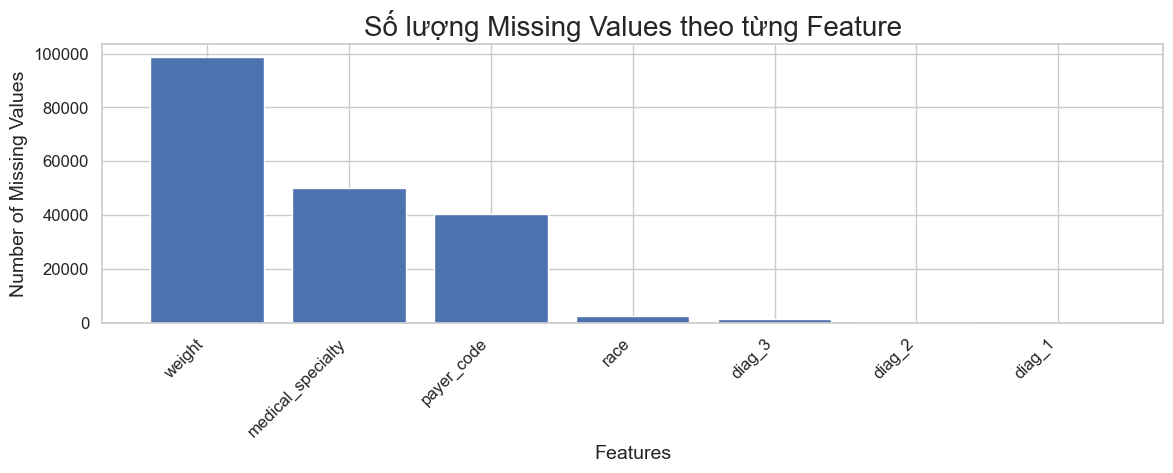

Số biến số: 8; số biến phân loại: 39
Tập train: 81,613 dòng; tập test: 20,153 dòng
Số bệnh nhân xuất hiện ở cả hai tập: 0
Train:
readmitted
0    53.729185
1    46.270815
Name: proportion, dtype: float64

Test:
readmitted
0    54.651913
1    45.348087
Name: proportion, dtype: float64


In [12]:

missing_counts = (raw_data == "?").sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)
display(missing_counts.rename("Số giá trị thiếu").to_frame())
plt.figure(figsize=(12, 5))
plt.bar(missing_counts.index, missing_counts.values)
plt.title("Số lượng Missing Values theo từng Feature")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

data = raw_data.copy()
data.replace("?", np.nan, inplace=True)


target = data["readmitted"].astype(str).str.strip().str.upper().ne("NO").astype("int8")
patient_groups = data["patient_nbr"].copy()
features = data.drop(columns=["readmitted", "encounter_id", "patient_nbr"])

id_columns = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
numeric_features = [
    column for column in features.select_dtypes(include="number").columns
    if column not in id_columns
]
categorical_features = [column for column in features.columns if column not in numeric_features]
print(f"Số biến số: {len(numeric_features)}; số biến phân loại: {len(categorical_features)}")

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_indices, test_indices = next(splitter.split(features, target, groups=patient_groups))
X_train, X_test = features.iloc[train_indices], features.iloc[test_indices]
y_train, y_test = target.iloc[train_indices], target.iloc[test_indices]
train_patients = set(patient_groups.iloc[train_indices])
test_patients = set(patient_groups.iloc[test_indices])
print(f"Tập train: {len(X_train):,} dòng; tập test: {len(X_test):,} dòng")
print(f"Số bệnh nhân xuất hiện ở cả hai tập: {len(train_patients & test_patients)}")
print("Train:")
print(y_train.value_counts(normalize=True) * 100)
print("\nTest:")
print(y_test.value_counts(normalize=True) * 100)

## 5. Chọn đặc trưng, huấn luyện và đánh giá mô hình

`SelectKBest(f_classif, k=50)` chọn 50 đặc trưng có điểm thống kê cao nhất sau tiền xử lý. Bộ chọn nằm trong pipeline nên chỉ được fit bằng dữ liệu train; các mô hình và phần đánh giá bên dưới tiếp tục dùng cùng luồng xử lý.

In [ ]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ],
    sparse_threshold=0.3,
)
feature_preprocessor = clone(preprocessor)

X_train_processed = feature_preprocessor.fit_transform(X_train)
X_test_processed = feature_preprocessor.transform(X_test)

selector = SelectKBest(
    score_func=f_classif,
    k=50
)

X_train_selected = selector.fit_transform(X_train_processed, y_train)
X_test_selected = selector.transform(X_test_processed)

print("Số lượng đặc trưng ban đầu:", X_train_processed.shape[1])
print("Số lượng đặc trưng sau lựa chọn:", X_train_selected.shape[1])

feature_names = feature_preprocessor.get_feature_names_out()
selected_features = feature_names[selector.get_support()]

feature_scores = pd.DataFrame({
    "Feature": feature_names,
    "Score": selector.scores_,
    "Selected": selector.get_support()
})

feature_scores = feature_scores.sort_values(
    "Score",
    ascending=False
).reset_index(drop=True)

display(feature_scores.head(50))

print("Các đặc trưng được lựa chọn:")
for feature in selected_features:
    print(feature)


models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, solver="liblinear", class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, max_depth=20, min_samples_leaf=2,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, tree_method="hist",
        eval_metric="logloss", n_jobs=-1, random_state=42,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=250, learning_rate=0.05, num_leaves=31,
        n_jobs=-1, verbosity=-1, random_state=42,
    ),
}

fitted_models = {}
model_results = []

for model_name, estimator in models.items():

    estimator.fit(X_train_selected, y_train)

    predictions = estimator.predict(X_test_selected)
    probabilities = estimator.predict_proba(X_test_selected)[:, 1]

    model_results.append({
        "Mô hình": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    })

    fitted_models[model_name] = estimator

    print(f"Mô hình huấn luyện: {model_name}")


model_comparison = pd.DataFrame(model_results).sort_values(
    "Balanced accuracy",
    ascending=False
).reset_index(drop=True)

display(
    model_comparison.style.format({
        column: "{:.3f}"
        for column in model_comparison.columns[1:]
    })
)

Số lượng đặc trưng ban đầu: 2424
Số lượng đặc trưng sau lựa chọn: 50


c:\Users\skyge\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [0 0 0 0] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
c:\Users\skyge\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,Feature,Score,Selected
0,numeric__number_inpatient,3950.234500,True
1,categorical__discharge_disposition_id_11,1176.596092,True
2,numeric__number_diagnoses,1046.565913,True
3,numeric__number_emergency,817.860763,True
4,numeric__number_outpatient,551.840151,True
5,categorical__admission_source_id_7,459.019596,True
6,categorical__diag_1_428,399.722667,True
7,categorical__diabetesMed_No,321.418044,True
8,categorical__diabetesMed_Yes,321.418044,True
9,categorical__discharge_disposition_id_6,294.387937,True


Các đặc trưng được lựa chọn:
numeric__time_in_hospital
numeric__num_lab_procedures
numeric__num_procedures
numeric__num_medications
numeric__number_outpatient
numeric__number_emergency
numeric__number_inpatient
numeric__number_diagnoses
categorical__admission_type_id_3
categorical__admission_type_id_6
categorical__discharge_disposition_id_3
categorical__discharge_disposition_id_6
categorical__discharge_disposition_id_11
categorical__discharge_disposition_id_13
categorical__discharge_disposition_id_14
categorical__admission_source_id_1
categorical__admission_source_id_4
categorical__admission_source_id_6
categorical__admission_source_id_7
categorical__payer_code_BC
categorical__payer_code_MC
categorical__medical_specialty_ObstetricsandGynecology
categorical__medical_specialty_Orthopedics-Reconstructive
categorical__medical_specialty_Surgery-Cardiovascular/Thoracic
categorical__medical_specialty_Surgery-Neuro
categorical__diag_1_250.6
categorical__diag_1_278
categorical__diag_1_428
categ

,Mô hình,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.642,0.639,0.605,0.608,0.606,0.695
1,LightGBM,0.646,0.638,0.624,0.552,0.586,0.700
2,XGBoost,0.647,0.637,0.628,0.540,0.581,0.700
3,Logistic Regression,0.635,0.631,0.601,0.584,0.592,0.689


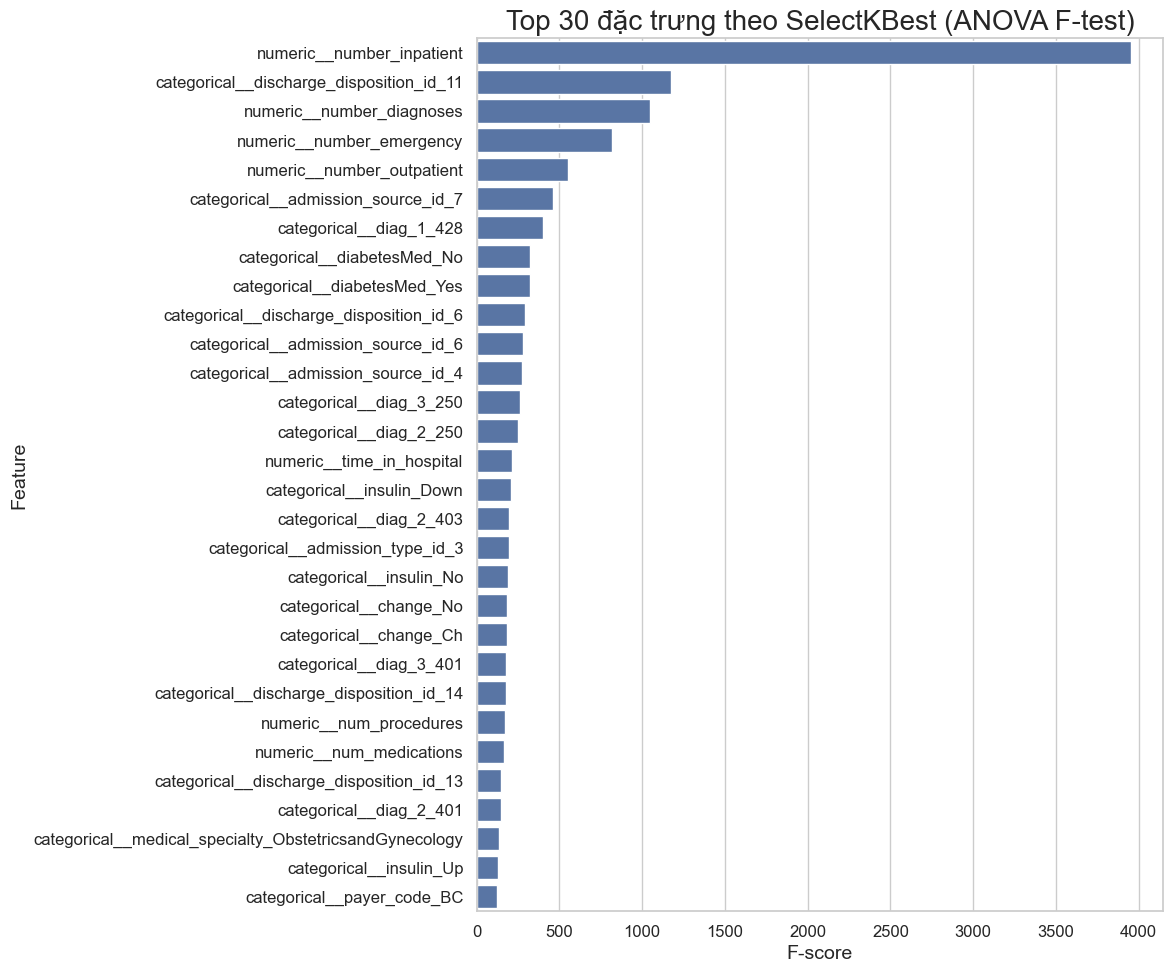

In [15]:
feature_scores = pd.DataFrame({
    "Feature": feature_names,
    "Score": selector.scores_
})

feature_scores = feature_scores.sort_values(
    "Score", ascending=False
)

plt.figure(figsize=(12, 10))

sns.barplot(
    data=feature_scores.head(30),
    x="Score",
    y="Feature",
    color=sns.color_palette("deep")[0]
)

plt.title("Top 30 đặc trưng theo SelectKBest (ANOVA F-test)")
plt.xlabel("F-score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

number_inpatient
0      38.494751
1      54.761539
2      64.935237
3      69.715626
4      74.229346
5      80.049261
6      84.166667
7      80.970149
8      90.728477
9      88.288288
10     85.245902
11    100.000000
12     88.235294
13     90.000000
14    100.000000
15    100.000000
16     66.666667
17    100.000000
18    100.000000
19    100.000000
21    100.000000
Name: readmitted, dtype: float64

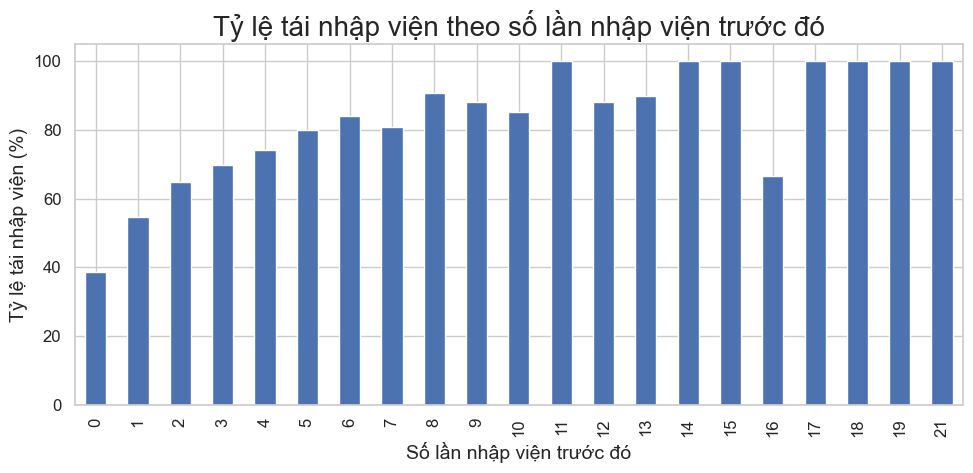

In [18]:
# plt.figure(figsize=(10, 5))

# sns.countplot(
#     data=raw_data,
#     x="number_inpatient",
#     hue="readmitted"
# )

# plt.title("Phân phối tái nhập viện theo số lần nhập viện trước đó")
# plt.xlabel("Số lần nhập viện trước đó")
# plt.ylabel("Số lượng bệnh nhân")
# plt.tight_layout()
# plt.show()
readmission_rate = raw_data.groupby(
    "number_inpatient"
)["readmitted"].apply(
    lambda x: (x != "NO").mean() * 100
)

display(readmission_rate)

readmission_rate.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Tỷ lệ tái nhập viện theo số lần nhập viện trước đó")
plt.xlabel("Số lần nhập viện trước đó")
plt.ylabel("Tỷ lệ tái nhập viện (%)")
plt.tight_layout()
plt.show()

,total_patients,readmitted,readmission_rate
number_inpatient,,,
0,67630,26034,38.49%
1,19521,10690,54.76%
2,7566,4913,64.94%
3,3411,2378,69.72%
4,1622,1204,74.23%
5,812,650,80.05%
6,480,404,84.17%
7,268,217,80.97%
8,151,137,90.73%


,count,sum,mean
inpatient_group,,,
0,67630,26034,38.494751
1,19521,10690,54.761539
2,7566,4913,64.935237
3,3411,2378,69.715626
4,1622,1204,74.229346
5+,2016,1683,83.482143


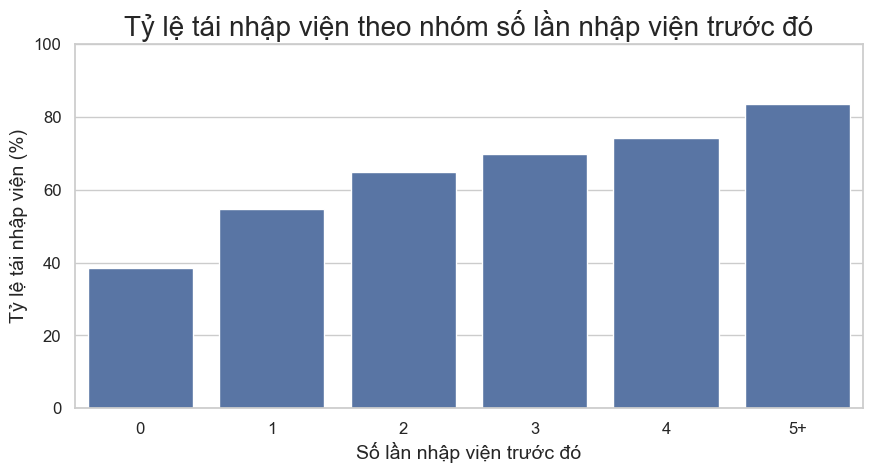

In [19]:
# Tạo biến nhị phân tái nhập viện
temp = raw_data.copy()

temp["is_readmitted"] = (
    temp["readmitted"] != "NO"
).astype(int)

# Tổng hợp số lượng và tỷ lệ
readmission_analysis = temp.groupby(
    "number_inpatient"
).agg(
    total_patients=("is_readmitted", "count"),
    readmitted=("is_readmitted", "sum"),
    readmission_rate=("is_readmitted", "mean")
)

readmission_analysis["readmission_rate"] *= 100

display(
    readmission_analysis.style.format({
        "readmission_rate": "{:.2f}%"
    })
)


temp = raw_data.copy()

temp["is_readmitted"] = (
    temp["readmitted"] != "NO"
).astype(int)

temp["inpatient_group"] = temp["number_inpatient"].apply(
    lambda x: str(x) if x < 5 else "5+"
)

group_analysis = temp.groupby(
    "inpatient_group"
)["is_readmitted"].agg(
    ["count", "sum", "mean"]
)

group_analysis["mean"] *= 100

display(group_analysis)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=group_analysis.index,
    y=group_analysis["mean"],
    color=sns.color_palette("deep")[0]
)

plt.title("Tỷ lệ tái nhập viện theo nhóm số lần nhập viện trước đó")
plt.xlabel("Số lần nhập viện trước đó")
plt.ylabel("Tỷ lệ tái nhập viện (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

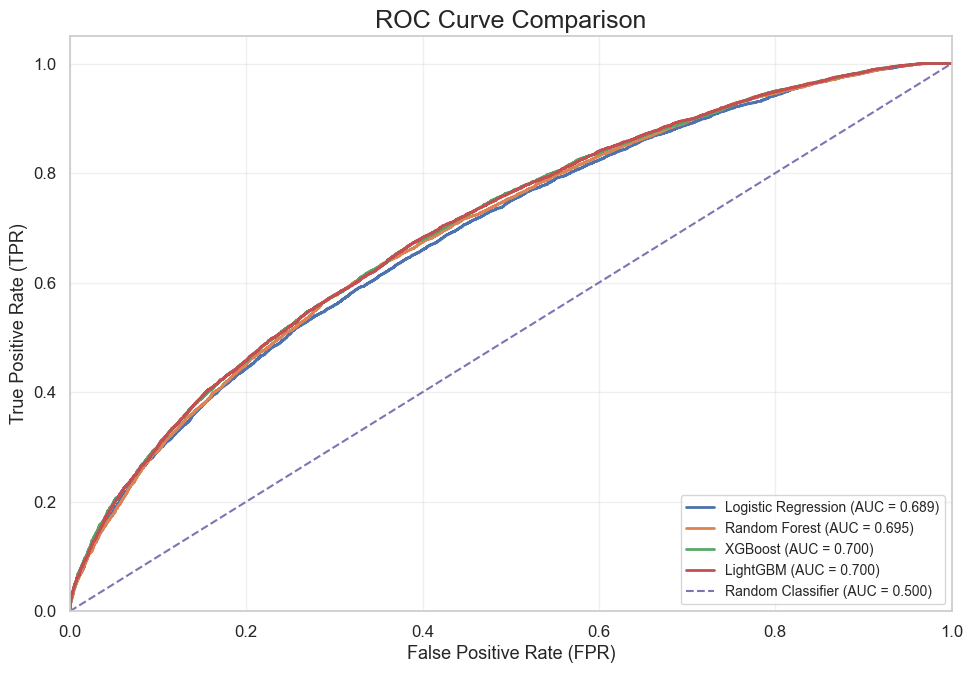

In [6]:

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for model_name, pipeline in fitted_models.items():

    # Lấy xác suất dự đoán thuộc class 1
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    # Tính False Positive Rate và True Positive Rate
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)

    # Tính diện tích dưới đường ROC
    roc_auc = auc(fpr, tpr)

    # Vẽ đường ROC
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {roc_auc:.3f})"
    )

# Đường phân loại ngẫu nhiên
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.500)"
)

plt.title("ROC Curve Comparison", fontsize=18)
plt.xlabel("False Positive Rate (FPR)", fontsize=13)
plt.ylabel("True Positive Rate (TPR)", fontsize=13)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


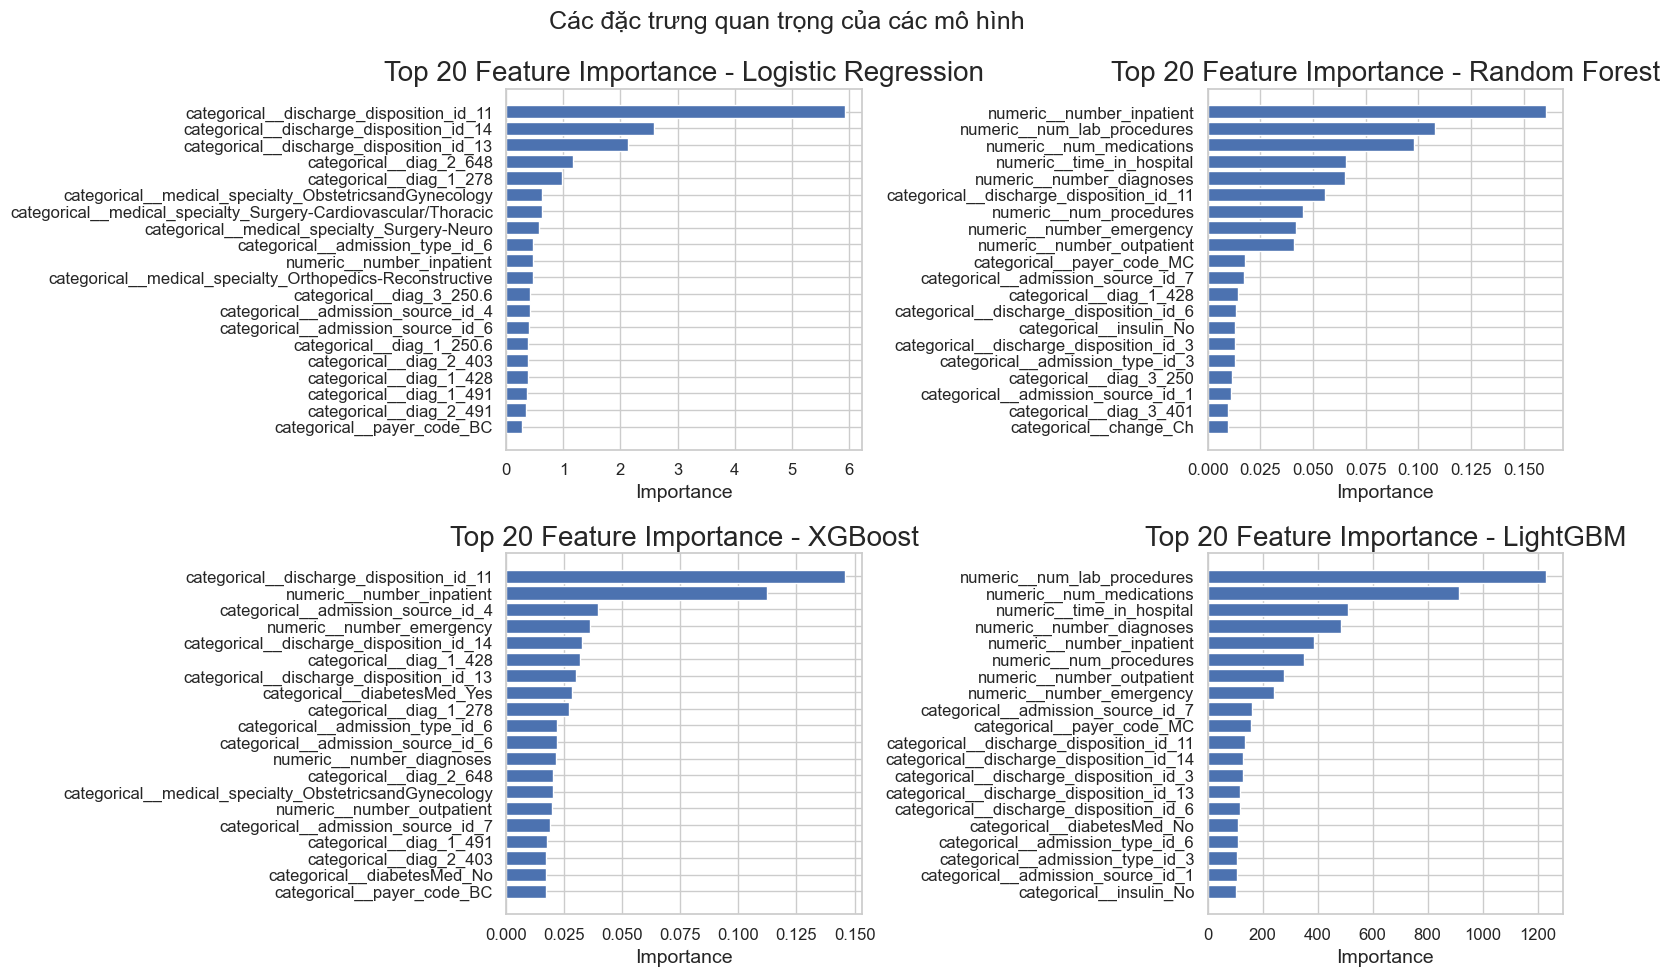

In [7]:
importance_frames = []

for model_name, pipeline in fitted_models.items():
    classifier = pipeline.named_steps["classifier"]
    feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()
    feature_names = feature_names[pipeline.named_steps["feature_selection"].get_support()]

    if hasattr(classifier, "feature_importances_"):
        importance_values = classifier.feature_importances_
    elif hasattr(classifier, "coef_"):
        importance_values = np.abs(classifier.coef_).mean(axis=0)
    else:
        print("Lỗi!")

    importance_frames.append(
        pd.DataFrame({
            "Mô hình": model_name,
            "Feature": feature_names,
            "Importance": importance_values,
        })
    )

feature_importance = pd.concat(importance_frames, ignore_index=True)
model_names = list(fitted_models)
n_cols = 2
n_rows = int(np.ceil(len(model_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = np.asarray(axes).reshape(-1)

for ax, model_name in zip(axes, model_names):
    top_features = (
        feature_importance[feature_importance["Mô hình"] == model_name]
        .nlargest(20, "Importance")
        .sort_values("Importance")
    )
    ax.barh(top_features["Feature"], top_features["Importance"], color=sns.color_palette("deep")[0])
    ax.set_title(f"Top 20 Feature Importance - {model_name}")
    ax.set_xlabel("Importance")
    ax.set_ylabel("")

for ax in axes[len(model_names):]:
    ax.set_visible(False)

fig.suptitle("Các đặc trưng quan trọng của các mô hình", fontsize=18)
fig.tight_layout()
plt.show()

## 6. Thực hiện bằng LazyPredict


In [8]:
from lazypredict.Supervised import LazyClassifier

X_lazy_train, _, y_lazy_train, _ = train_test_split(
    X_train,
    y_train,
    train_size=min(8000, len(X_train) - 1),
    stratify=y_train,
    random_state=42,
)
X_lazy_test, _, y_lazy_test, _ = train_test_split(
    X_test,
    y_test,
    train_size=min(2000, len(X_test) - 1),
    stratify=y_test,
    random_state=42,
)

lazy_preprocessor = clone(preprocessor)
X_lazy_train_encoded = lazy_preprocessor.fit_transform(X_lazy_train, y_lazy_train)
X_lazy_test_encoded = lazy_preprocessor.transform(X_lazy_test)
if hasattr(X_lazy_train_encoded, "toarray"):
    X_lazy_train_encoded = X_lazy_train_encoded.toarray()
if hasattr(X_lazy_test_encoded, "toarray"):
    X_lazy_test_encoded = X_lazy_test_encoded.toarray()

lazy_classifier = LazyClassifier(verbose=0, ignore_warnings=True, predictions=False)
lazy_results, _ = lazy_classifier.fit(
    X_lazy_train_encoded,
    X_lazy_test_encoded,
    y_lazy_train,
    y_lazy_test,
)
display(lazy_results.sort_values("Balanced Accuracy", ascending=False).style.format("{:.3f}"))

c:\Users\skyge\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
High-dimensional dataset (1538 features). Some models may be slow or fail. Consider dimensionality reduction.


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
LGBMClassifier,0.629,0.622,0.658,0.627,0.627,0.629,1.228
XGBClassifier,0.615,0.607,0.646,0.612,0.612,0.615,1.401
RandomForestClassifier,0.611,0.598,0.648,0.603,0.607,0.611,7.026
AdaBoostClassifier,0.613,0.597,0.628,0.601,0.611,0.613,9.261
BernoulliNB,0.599,0.596,0.639,0.599,0.599,0.599,1.260
BaggingClassifier,0.603,0.589,0.633,0.594,0.599,0.603,9.458
ExtraTreesClassifier,0.598,0.588,0.628,0.593,0.594,0.598,22.717
LinearSVC,0.593,0.587,0.617,0.592,0.591,0.593,32.988
LogisticRegression,0.591,0.584,0.609,0.589,0.589,0.591,1.005
